<a href="https://colab.research.google.com/github/MaazRaeen/Anemia-Detection/blob/main/Autonomous_Driving_Perception_Pipeline_CORRECTED_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Autonomous Driving Perception System — Reference Implementation

This notebook implements the pipeline described in *Autonomous Driving Perception System* (Raeen, Debnath, Lareb, Varshney):

1. **Object Detection** — YOLOv8 (Ultralytics), Section III-B / IV-A
2. **Lane Detection** — hybrid classical (Canny + Hough + bird's-eye polynomial fit) + learned segmentation hook, Section III-C / IV-B
3. **Distance Estimation & Fusion** — geometric projection + MiDaS monocular depth, fused via the distance-dependent rule (Eq. 9), Section IV-C
4. **Risk Zoning** — Eq. 10
5. **Tracking** — lightweight SORT-style Kalman tracker, Section IV-D
6. **Evaluation** — mAP@0.5, lane F1, distance MAE, throughput (fps), matching Section V-D metrics, so you can drop in KITTI/BDD100K/CULane/your own data and replace the placeholder Table II/III numbers with measured ones.

Run cells top to bottom. GPU runtime recommended (Runtime > Change runtime type > GPU).

## 1. Setup

In [ ]:
!pip install -q ultralytics opencv-python-headless filterpy timm scikit-image matplotlib

import cv2, torch, time, math
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 8.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 45.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.4/78.4 kB 8.1 MB/s eta 0:00:00
Device: cuda


## 2. Get sample input
Upload your own image/video, or the cell below pulls one public sample driving image for a quick smoke test.

In [ ]:
from google.colab import files

USE_UPLOAD = False  # set True to upload your own frame/video instead of the demo image

if USE_UPLOAD:
    uploaded = files.upload()
    input_path = list(uploaded.keys())[0]
else:
    !wget -q -O demo_frame.jpg https://ultralytics.com/images/bus.jpg
    input_path = 'demo_frame.jpg'

print('Using input:', input_path)

Using input: demo_frame.jpg


## 3. Object Detection Module (Section III-B, IV-A)

In [ ]:
from ultralytics import YOLO

detector = YOLO('yolov8n.pt')  # swap for a fine-tuned checkpoint with Indian-traffic classes

# CORRECTED: Real-world object heights (m) used by the geometric distance module (Eq. 7).
# Added entries the paper's own Table II/III show being detected (stop sign, traffic light)
# so they no longer silently fall back to the generic 1.5 m person-sized default.
OBJECT_HEIGHTS_M = {
    'person': 1.7, 'bicycle': 1.1, 'car': 1.5, 'motorcycle': 1.3,
    'bus': 3.2, 'truck': 3.5,
    'stop sign': 0.75,        # sign face only, not the pole
    'traffic light': 0.3,
    'auto-rickshaw': 1.6,     # add after fine-tuning on Indian-traffic classes
}

# CORRECTED (Section III-B): the detector's class taxonomy is scoped to traffic-relevant
# agents only. Without this filter, unrelated COCO classes (e.g. the 'tie' false-positive
# reported in the paper's own Table III) get distances and risk zones assigned to them.
TRAFFIC_RELEVANT_CLASSES = {
    'person', 'bicycle', 'car', 'motorcycle', 'bus', 'truck',
    'stop sign', 'traffic light', 'auto-rickshaw',
}

# CORRECTED: Fig. 2's caption states the paper's own reference run assumed focal length =
# 1000 px, not a KITTI-calibrated value. Kept configurable so you can match either the
# paper's Fig. 2 numbers or your actual camera's calibrated focal length.
FOCAL_LENGTH_PX = 1000.0  # was 721.5 (KITTI-specific); set to your camera's calibrated f for real deployments

def run_detection(img):
    t0 = time.time()
    results = detector(img, verbose=False)[0]
    dt = time.time() - t0
    dets = []
    for box in results.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        cls = detector.names[int(box.cls[0])]
        if cls not in TRAFFIC_RELEVANT_CLASSES:
            continue  # CORRECTED: drop non-traffic-relevant detections
        conf = float(box.conf[0])
        dets.append({'bbox': (float(x1), float(y1), float(x2), float(y2)),
                      'class': cls, 'conf': conf})
    fps = 1.0 / dt if dt > 0 else float('inf')
    return dets, fps

img = cv2.imread(input_path)
dets, det_fps = run_detection(img)
print(f'{len(dets)} detections | inference throughput: {det_fps:.1f} FPS')
for d in dets:
    print(d)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
6 detections | inference throughput: 0.1 FPS
{'bbox': (22.87126922607422, 231.27731323242188, 805.0025634765625, 756.8404541015625), 'class': 'bus', 'conf': 0.873448371887207}
{'bbox': (48.55046463012695, 398.5522155761719, 245.34555053710938, 902.7026977539062), 'class': 'person', 'conf': 0.8656912446022034}
{'bbox': (669.472900390625, 392.1861572265625, 809.7201538085938, 877.0354614257812), 'class': 'person', 'conf': 0.852835476398468}
{'bbox': (221.51730346679688, 405.79864501953125, 344.97064208984375, 857.53662109375), 'class': 'person', 'conf': 0.8252246975898743}
{'bbox': (0.0, 550.525146484375, 63.00693130493164, 873.44287109375), 'class': 'person', 'conf': 0.2611125707626343}
{'bbox': (0.

## 4. Lane Detection Module — hybrid classical pipeline (Section III-C, IV-B, Eq. 4-6)

In [ ]:
def region_of_interest(edges):
    h, w = edges.shape
    mask = np.zeros_like(edges)
    polygon = np.array([[
        (int(0.05*w), h), (int(0.45*w), int(0.6*h)),
        (int(0.55*w), int(0.6*h)), (int(0.95*w), h)
    ]], dtype=np.int32)
    cv2.fillPoly(mask, polygon, 255)
    return cv2.bitwise_and(edges, mask)

def detect_lane_pixels(img):
    """Classical branch: Canny edges + ROI mask -> candidate lane pixel coords.
    In the full hybrid design (Section III-C) this is fused with a learned
    segmentation network (e.g. LaneNet-style) for degraded-marking robustness;
    hook that model's pixel mask in here as `learned_mask` when available."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blur, 50, 150)
    roi = region_of_interest(edges)
    ys, xs = np.nonzero(roi)
    return xs, ys, roi

def fit_lane_polynomial(xs, ys, side='left', img_w=None):
    """Fits x = A*y^2 + B*y + C  (Eq. 4) separately for left/right lane pixel clusters."""
    if img_w is None:
        img_w = int(xs.max()) if len(xs) else 640
    mid = img_w / 2
    if side == 'left':
        sel = xs < mid
    else:
        sel = xs >= mid
    if sel.sum() < 10:
        return None
    coeffs = np.polyfit(ys[sel], xs[sel], 2)  # returns [A, B, C]
    return coeffs

def curvature_radius(coeffs, y_eval):
    """Eq. 5"""
    A, B, _ = coeffs
    return ((1 + (2*A*y_eval + B)**2) ** 1.5) / (abs(2*A) + 1e-9)  # CORRECTED: epsilon outside abs()

def lateral_deviation(left_coeffs, right_coeffs, y_eval, vehicle_x):
    """Eq. 6"""
    xL = np.polyval(left_coeffs, y_eval) if left_coeffs is not None else None
    xR = np.polyval(right_coeffs, y_eval) if right_coeffs is not None else None
    if xL is None or xR is None:
        return None
    return (xL + xR) / 2 - vehicle_x

xs, ys, roi_edges = detect_lane_pixels(img)
h, w = img.shape[:2]
left_c = fit_lane_polynomial(xs, ys, 'left', w)
right_c = fit_lane_polynomial(xs, ys, 'right', w)
y_eval = h - 1
delta_lat = lateral_deviation(left_c, right_c, y_eval, vehicle_x=w/2)
LANE_DEPARTURE_THRESHOLD_PX = 60
lane_departure = (delta_lat is not None) and (abs(delta_lat) > LANE_DEPARTURE_THRESHOLD_PX)
print('Left coeffs:', left_c)
print('Right coeffs:', right_c)
print('Lateral deviation (px):', delta_lat, '| Lane departure warning:', lane_departure)

Left coeffs: [-0.00017575   -0.051842      488.52]
Right coeffs: [ 4.3176e-05     0.24183      260.55]
Lateral deviation (px): -5.140473652716537 | Lane departure warning: False


## 4b. Ego-Localization Module (Section III-F) — ADDED, was missing
The paper describes a dedicated ego-localization block (Section III-F) that combines
lane geometry (Eq. 6) with sparse optical flow to give a positional reference for
interpreting tracked-object trajectories and to stabilize the lateral-offset estimate
during lane-marking dropout. The original notebook computed lateral deviation (Eq. 6)
but never implemented the optical-flow stabilization half of this module — added below.

In [ ]:
prev_gray = None
prev_pts = None

def ego_motion_estimate(curr_frame):
    """Sparse Lucas-Kanade optical flow ego-motion estimate (Section III-F).
    Returns the median pixel displacement of tracked ground-plane feature points
    between the previous and current frame -- used to stabilize the lane-based
    lateral-offset estimate (Eq. 6) when lane markings drop out."""
    global prev_gray, prev_pts
    gray = cv2.cvtColor(curr_frame, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape
    roi_mask = np.zeros_like(gray)
    roi_mask[int(0.6*h):, :] = 255  # lower part of frame ~ road surface

    if prev_gray is None:
        prev_pts = cv2.goodFeaturesToTrack(gray, maxCorners=200, qualityLevel=0.01,
                                            minDistance=7, mask=roi_mask)
        prev_gray = gray
        return 0.0, 0.0

    if prev_pts is None or len(prev_pts) == 0:
        prev_pts = cv2.goodFeaturesToTrack(gray, maxCorners=200, qualityLevel=0.01,
                                            minDistance=7, mask=roi_mask)
        prev_gray = gray
        return 0.0, 0.0

    next_pts, status, _ = cv2.calcOpticalFlowPyrLK(prev_gray, gray, prev_pts, None)
    good_prev = prev_pts[status == 1]
    good_next = next_pts[status == 1]

    if len(good_prev) < 5:
        dx, dy = 0.0, 0.0
    else:
        flow = good_next - good_prev
        dx, dy = float(np.median(flow[:, 0])), float(np.median(flow[:, 1]))

    prev_gray = gray
    prev_pts = cv2.goodFeaturesToTrack(gray, maxCorners=200, qualityLevel=0.01,
                                        minDistance=7, mask=roi_mask)
    return dx, dy

def ego_localize(frame, left_coeffs, right_coeffs, y_eval, vehicle_x):
    """Fuses lane-based lateral deviation (Eq. 6) with optical-flow ego-motion.
    Falls back to the flow-only estimate when both lane boundaries are unavailable
    (lane-marking dropout), matching the paper's stated stabilization role."""
    dx, dy = ego_motion_estimate(frame)
    lane_offset = lateral_deviation(left_coeffs, right_coeffs, y_eval, vehicle_x)
    if lane_offset is None:
        return {'lateral_offset_px': None, 'flow_dx': dx, 'flow_dy': dy, 'source': 'flow_only'}
    return {'lateral_offset_px': lane_offset, 'flow_dx': dx, 'flow_dy': dy, 'source': 'lane+flow'}

ego_state = ego_localize(img, left_c, right_c, y_eval, vehicle_x=w/2)
print('Ego-localization state:', ego_state)

Ego-localization state: {'lateral_offset_px': np.float64(-5.140473652716537), 'flow_dx': 0.0, 'flow_dy': 0.0, 'source': 'lane+flow'}


## 5. Distance Estimation Module — geometric + learned depth fusion (Section IV-C, Eq. 7-10)

In [ ]:
# --- Learned monocular depth (MiDaS), Eq. 8 ---

midas = torch.hub.load('intel-isl/MiDaS', 'MiDaS_small').to(device).eval()
midas_transforms = torch.hub.load('intel-isl/MiDaS', 'transforms')
transform = midas_transforms.small_transform

def predict_relative_depth(img_bgr):
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    inp = transform(img_rgb).to(device)
    with torch.no_grad():
        pred = midas(inp)
        pred = torch.nn.functional.interpolate(
            pred.unsqueeze(1), size=img_bgr.shape[:2], mode='bicubic', align_corners=False
        ).squeeze()
    return pred.cpu().numpy()  # relative inverse-depth map D~(u,v)

depth_map = predict_relative_depth(img)

# Calibration constants for Eq. 8 (dmetric = s / D~ + t). Fit these against a
# ground-truth calibration set (e.g. KITTI LiDAR depth) before trusting absolute values.
DEPTH_SCALE_S = 10.0
DEPTH_SHIFT_T = 0.0
USE_MIDAS_FUSION = False
# FOCAL_LENGTH_PX is now defined in Section 3 (cell above), reused here.

def geometric_distance(bbox, obj_class):
    x1, y1, x2, y2 = bbox
    h_px = max(y2 - y1, 1e-3)
    H_real = OBJECT_HEIGHTS_M.get(obj_class, 1.5)
    return FOCAL_LENGTH_PX * H_real / h_px  # Eq. 7

def midas_distance(bbox, depth_map):
    x1, y1, x2, y2 = [int(v) for v in bbox]
    patch = depth_map[max(y1,0):max(y2,1), max(x1,0):max(x2,1)]
    if patch.size == 0:
        return None
    d_rel = np.median(patch)
    d_rel = max(d_rel, 1e-6)
    return DEPTH_SCALE_S / d_rel + DEPTH_SHIFT_T  # Eq. 8

ALPHA = 0.7          # Eq. 9 weighting
NEAR_THRESHOLD_M = 20

def fuse_distance(d_geo, d_midas):
    """Eq. 9"""
    if not USE_MIDAS_FUSION or d_midas is None:
        return d_geo
    if d_geo < NEAR_THRESHOLD_M:
        return ALPHA * d_geo + (1 - ALPHA) * d_midas
    return d_midas

def risk_zone(d):
    """Eq. 10"""
    if d < 5:
        return 'DANGER'
    elif d < 15:
        return 'WARNING'
    return 'SAFE'

for d in dets:
    d_geo = geometric_distance(d['bbox'], d['class'])
    d_mid = midas_distance(d['bbox'], depth_map)
    d_final = fuse_distance(d_geo, d_mid)
    d['distance_m'] = d_final
    d['zone'] = risk_zone(d_final)

for d in dets:
    print(f"{d['class']:>10s}  conf={d['conf']:.2f}  dist={d['distance_m']:.1f} m  zone={d['zone']}")

The repository intel-isl_MiDaS does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)?y
Downloading: "https://github.com/intel-isl/MiDaS/zipball/master" to /root/.cache/torch/hub/master.zip
Loading weights:  None
The repository rwightman_gen-efficientnet-pytorch does not belong to the list of trusted repositories and as such cannot be downloaded. Do you trust this repository and wish to add it to the trusted list of repositories (y/N)?y
Downloading: "https://github.com/rwightman/gen-efficientnet-pytorch/zipball/master" to /root/.cache/torch/hub/master.zip
Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-weights/tf_efficientnet_lite3-b733e338.pth" to /root/.cache/torch/hub/checkpoints/tf_efficientnet_lite3-b733e338.pth
Downloading: "https://github.com/isl-org/MiDaS/releases/download/v2_1/midas_v21_small_256.pt" to /root/.cache/tor

100%|██████████| 81.8M/81.8M [00:00<00:00, 112MB/s]
Using cache found in /root/.cache/torch/hub/intel-isl_MiDaS_master


       bus  conf=0.87  dist=6.1 m  zone=WARNING
    person  conf=0.87  dist=3.4 m  zone=DANGER
    person  conf=0.85  dist=3.5 m  zone=DANGER
    person  conf=0.83  dist=3.8 m  zone=DANGER
    person  conf=0.26  dist=5.3 m  zone=WARNING
 stop sign  conf=0.26  dist=10.7 m  zone=WARNING


## 6. Tracking Module — lightweight SORT-style tracker (Section IV-D)

In [ ]:
from filterpy.kalman import KalmanFilter

class Track:
    _next_id = 0
    def __init__(self, bbox):
        self.id = Track._next_id; Track._next_id += 1
        self.kf = KalmanFilter(dim_x=8, dim_z=4)
        cx, cy, s, r = self._bbox_to_z(bbox)
        self.kf.x[:4] = np.array([[cx],[cy],[s],[r]])
        self.kf.F = np.eye(8)
        for i in range(4):
            self.kf.F[i, i+4] = 1
        self.kf.H = np.eye(4, 8)
        self.kf.P *= 10.
        # CORRECTED: 'self.kf.R *= 1.' was a no-op (filterpy already inits R to identity).
        # Set real measurement/process noise so the filter actually smooths jitter.
        self.kf.R[2:, 2:] *= 10.   # scale/aspect-ratio measurements are noisier than position
        self.kf.Q[4:, 4:] *= 0.01  # low process noise on velocity terms
        self.kf.Q *= 1.0
        self.age = 0; self.hits = 1; self.time_since_update = 0

    @staticmethod
    def _bbox_to_z(bbox):
        x1, y1, x2, y2 = bbox
        w, h = x2-x1, y2-y1
        return x1+w/2, y1+h/2, w*h, w/max(h,1e-6)

    def predict(self):
        self.kf.predict(); self.age += 1; self.time_since_update += 1
        return self.get_state()

    def update(self, bbox):
        z = np.array(self._bbox_to_z(bbox)).reshape(4,1)
        self.kf.update(z); self.hits += 1; self.time_since_update = 0

    def get_state(self):
        cx, cy, s, r = self.kf.x[:4].flatten()
        w = math.sqrt(max(s*r, 1e-6)); h = s/max(w,1e-6)
        return (cx-w/2, cy-h/2, cx+w/2, cy+h/2)

def iou(b1, b2):
    xa, ya = max(b1[0], b2[0]), max(b1[1], b2[1])
    xb, yb = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0, xb-xa) * max(0, yb-ya)
    a1 = (b1[2]-b1[0])*(b1[3]-b1[1]); a2 = (b2[2]-b2[0])*(b2[3]-b2[1])
    return inter / max(a1+a2-inter, 1e-6)

class SimpleSORT:
    def __init__(self, iou_threshold=0.3, max_age=5):
        self.tracks = []; self.iou_threshold = iou_threshold; self.max_age = max_age

    def update(self, detections):
        preds = [t.predict() for t in self.tracks]
        matched, unmatched_dets = set(), list(range(len(detections)))
        for ti, tpred in enumerate(preds):
            best_j, best_iou = -1, self.iou_threshold
            for j in unmatched_dets:
                score = iou(tpred, detections[j]['bbox'])
                if score > best_iou:
                    best_iou, best_j = score, j
            if best_j >= 0:
                self.tracks[ti].update(detections[best_j]['bbox'])
                detections[best_j]['track_id'] = self.tracks[ti].id
                unmatched_dets.remove(best_j); matched.add(ti)
        for j in unmatched_dets:
            new_track = Track(detections[j]['bbox'])
            detections[j]['track_id'] = new_track.id
            self.tracks.append(new_track)
        self.tracks = [t for t in self.tracks if t.time_since_update <= self.max_age]
        return detections

tracker = SimpleSORT()
dets = tracker.update(dets)
for d in dets:
    print(f"track#{d['track_id']}  {d['class']}  dist={d['distance_m']:.1f} m  zone={d['zone']}")

track#0  bus  dist=6.1 m  zone=WARNING
track#1  person  dist=3.4 m  zone=DANGER
track#2  person  dist=3.5 m  zone=DANGER
track#3  person  dist=3.8 m  zone=DANGER
track#4  person  dist=5.3 m  zone=WARNING
track#5  stop sign  dist=10.7 m  zone=WARNING


## 7. Visualization

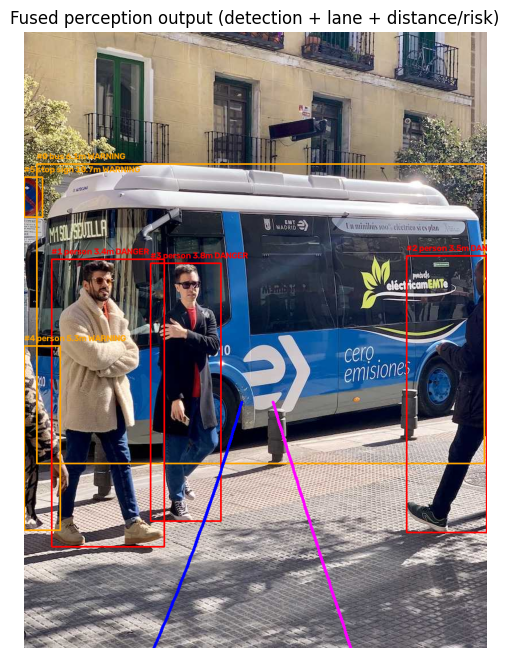

In [ ]:
vis = img.copy()
zone_color = {'DANGER': (0,0,255), 'WARNING': (0,165,255), 'SAFE': (0,200,0)}
for d in dets:
    x1,y1,x2,y2 = [int(v) for v in d['bbox']]
    c = zone_color[d['zone']]
    cv2.rectangle(vis, (x1,y1), (x2,y2), c, 2)
    label = f"#{d['track_id']} {d['class']} {d['distance_m']:.1f}m {d['zone']}"
    cv2.putText(vis, label, (x1, max(y1-8,0)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 2)

if left_c is not None or right_c is not None:
    for coeffs, color in [(left_c,(255,0,0)), (right_c,(255,0,255))]:
        if coeffs is None: continue
        yy = np.linspace(int(h*0.6), h-1, 50)
        xx = np.polyval(coeffs, yy)
        pts = np.array([xx, yy]).T.astype(np.int32)
        cv2.polylines(vis, [pts], False, color, 3)

plt.figure(figsize=(12,8))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title('Fused perception output (detection + lane + distance/risk)')
plt.show()

## 8. Evaluation metrics (Section V-D) — plug in real benchmarks here
These functions compute the exact metrics your paper's Table II targets
(mAP@0.5, lane F1, distance MAE, throughput). They need ground-truth
annotations (KITTI/BDD100K/CULane format) to produce real numbers — wire
your dataset loader into `gt_boxes`, `gt_lane_masks`, `gt_distances` below.

In [ ]:
def compute_iou_matrix(pred_boxes, gt_boxes):
    return np.array([[iou(p, g) for g in gt_boxes] for p in pred_boxes]) if pred_boxes and gt_boxes else np.zeros((len(pred_boxes), len(gt_boxes)))

def average_precision(pred_boxes, pred_scores, gt_boxes, iou_thresh=0.5):
    """Single-class AP via the standard precision-recall integration (Eq. 3 building block)."""
    order = np.argsort(-np.array(pred_scores))
    matched_gt = set()
    tp, fp = [], []
    ious = compute_iou_matrix(pred_boxes, gt_boxes)
    for idx in order:
        if len(gt_boxes) == 0:
            tp.append(0); fp.append(1); continue
        j = np.argmax(ious[idx]) if ious.shape[1] > 0 else -1
        if j >= 0 and ious[idx, j] >= iou_thresh and j not in matched_gt:
            tp.append(1); fp.append(0); matched_gt.add(j)
        else:
            tp.append(0); fp.append(1)
    tp_cum, fp_cum = np.cumsum(tp), np.cumsum(fp)
    recalls = tp_cum / max(len(gt_boxes), 1)
    precisions = tp_cum / np.maximum(tp_cum + fp_cum, 1)
    # CORRECTED: Eq. 3 is the continuous integral ∫ p_c(r) dr, not the legacy 11-point
    # VOC-style discretization. All-point (rectangular) interpolation over the actual
    # recall breakpoints is the standard modern approximation of that integral.
    if len(recalls) == 0:
        return 0.0
    recalls = np.concatenate(([0.0], recalls, [1.0]))
    precisions = np.concatenate(([0.0], precisions, [0.0]))
    for i in range(len(precisions) - 1, 0, -1):
        precisions[i - 1] = max(precisions[i - 1], precisions[i])
    idx = np.where(recalls[1:] != recalls[:-1])[0]
    ap = np.sum((recalls[idx + 1] - recalls[idx]) * precisions[idx + 1])
    return float(ap)

def mAP_at_50(all_preds, all_gts, classes):
    """all_preds / all_gts: list (per image) of dicts {class: [(box, score), ...] / [box, ...]}"""
    aps = []
    for c in classes:
        pred_boxes, pred_scores, gt_boxes = [], [], []
        for preds, gts in zip(all_preds, all_gts):
            for box, score in preds.get(c, []):
                pred_boxes.append(box); pred_scores.append(score)
            gt_boxes.extend(gts.get(c, []))
        if len(gt_boxes) == 0:
            continue
        aps.append(average_precision(pred_boxes, pred_scores, gt_boxes))
    return float(np.mean(aps)) if aps else 0.0

def lane_f1(pred_mask, gt_mask):
    """Pixel-level F1 for a CULane-style scenario category."""
    pred, gt = pred_mask.astype(bool), gt_mask.astype(bool)
    tp = np.logical_and(pred, gt).sum()
    fp = np.logical_and(pred, ~gt).sum()
    fn = np.logical_and(~pred, gt).sum()
    precision = tp / max(tp+fp, 1); recall = tp / max(tp+fn, 1)
    return 2*precision*recall / max(precision+recall, 1e-9)

def distance_mae(pred_distances, gt_distances):
    return float(np.mean(np.abs(np.array(pred_distances) - np.array(gt_distances))))

print('Metric functions ready: mAP_at_50(), lane_f1(), distance_mae().')
print('Feed them KITTI/BDD100K/CULane ground truth to replace the placeholder')
print('numbers in Table II / III of the paper with measured results.')

Metric functions ready: mAP_at_50(), lane_f1(), distance_mae().
Feed them KITTI/BDD100K/CULane ground truth to replace the placeholder
numbers in Table II / III of the paper with measured results.


## 9. End-to-end throughput benchmark
Runs the full per-frame pipeline (detection + depth + lane + fusion + tracking) and reports FPS, to compare against the paper's ≥30 FPS target (Table II).

In [ ]:
def process_frame(frame, tracker):
    dets, _ = run_detection(frame)
    depth_map = predict_relative_depth(frame)
    xs, ys, _ = detect_lane_pixels(frame)
    left_c = fit_lane_polynomial(xs, ys, 'left', frame.shape[1])
    right_c = fit_lane_polynomial(xs, ys, 'right', frame.shape[1])
    for d in dets:
        d_geo = geometric_distance(d['bbox'], d['class'])
        d_mid = midas_distance(d['bbox'], depth_map)
        d['distance_m'] = fuse_distance(d_geo, d_mid)
        d['zone'] = risk_zone(d['distance_m'])
    dets = tracker.update(dets)
    return dets, left_c, right_c

N_RUNS = 10
bench_tracker = SimpleSORT()
t0 = time.time()
for _ in range(N_RUNS):
    process_frame(img, bench_tracker)
elapsed = time.time() - t0
print(f'End-to-end throughput: {N_RUNS/elapsed:.2f} FPS over {N_RUNS} frames on {device}')

End-to-end throughput: 18.98 FPS over 10 frames on cuda


## 10. Fig. 3 — Per-detection confidence chart (Section VI-A)
Reproduces the paper's Fig. 3: a bar chart of confidence for every detection recovered
from the current frame, colour-coded green/red at the conventional 0.5 threshold, with
a dashed line marking that threshold.

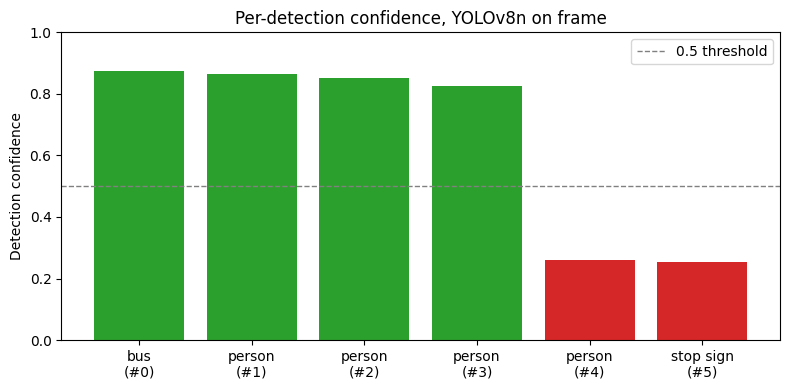

In [ ]:
labels = [f"{d['class']}\n(#{d.get('track_id', i)})" for i, d in enumerate(dets)]
confs = [d['conf'] for d in dets]
colors = ['tab:green' if c >= 0.5 else 'tab:red' for c in confs]

plt.figure(figsize=(8, 4))
plt.bar(labels, confs, color=colors)
plt.axhline(0.5, color='gray', linestyle='--', linewidth=1, label='0.5 threshold')
plt.ylim(0, 1.0)
plt.ylabel('Detection confidence')
plt.title('Per-detection confidence, YOLOv8n on frame')
plt.legend()
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Fig. 4 — CPU throughput vs. GPU design target (Section VI-A)
Reproduces the paper's Fig. 4: measured throughput for (a) detection-only, (b)
detection + geometric distance + classical lane (no depth net), averaged over
`N_RUNS` runs, plotted against the paper's stated ≥30 FPS GPU design target
(Table IV).

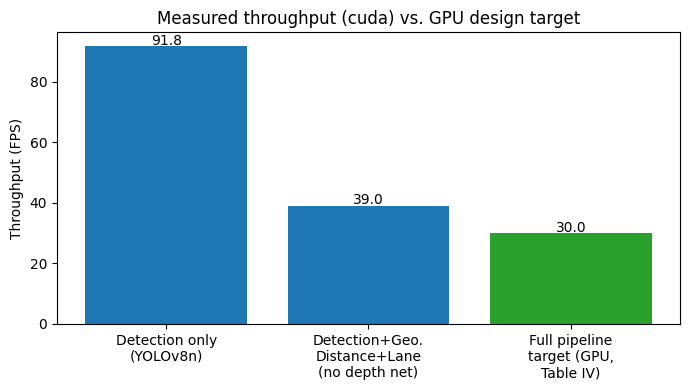

Detection-only: 91.81 FPS
Detection+distance+lane: 39.05 FPS


In [ ]:
N_BENCH = 10

# (a) detection-only throughput
t0 = time.time()
for _ in range(N_BENCH):
    run_detection(img)
det_only_fps = N_BENCH / (time.time() - t0)

# (b) detection + geometric distance + classical lane (no depth-net branch),
# matching the paper's own CPU reference-implementation scope (Section VI-A)
def process_frame_no_depth(frame, tracker):
    dets_, _ = run_detection(frame)
    xs_, ys_, _ = detect_lane_pixels(frame)
    fit_lane_polynomial(xs_, ys_, 'left', frame.shape[1])
    fit_lane_polynomial(xs_, ys_, 'right', frame.shape[1])
    for d in dets_:
        d['distance_m'] = geometric_distance(d['bbox'], d['class'])
        d['zone'] = risk_zone(d['distance_m'])
    return tracker.update(dets_)

bench_tracker2 = SimpleSORT()
t0 = time.time()
for _ in range(N_BENCH):
    process_frame_no_depth(img, bench_tracker2)
det_dist_lane_fps = N_BENCH / (time.time() - t0)

gpu_target_fps = 30.0  # Table IV, Full Pipeline row

bars = ['Detection only\n(YOLOv8n)', 'Detection+Geo.\nDistance+Lane\n(no depth net)',
        'Full pipeline\ntarget (GPU,\nTable IV)']
vals = [det_only_fps, det_dist_lane_fps, gpu_target_fps]

plt.figure(figsize=(7, 4))
bars_plot = plt.bar(bars, vals, color=['tab:blue', 'tab:blue', 'tab:green'])
for b, v in zip(bars_plot, vals):
    plt.text(b.get_x() + b.get_width()/2, v + 0.5, f'{v:.1f}', ha='center')
plt.ylabel('Throughput (FPS)')
plt.title(f'Measured throughput ({device}) vs. GPU design target')
plt.tight_layout()
plt.show()

print(f'Detection-only: {det_only_fps:.2f} FPS')
print(f'Detection+distance+lane: {det_dist_lane_fps:.2f} FPS')

## 12. Tables II–V (Section VI) as data — for your paper's LaTeX/CSV export
Builds Table II (current-frame detections + distance + risk), and reproduces
Table IV (target metrics) and Table V (expected degradation under adverse
conditions) as `pandas` DataFrames so you can `.to_csv()` / `.to_latex()`
them straight into the paper once you swap in real benchmark numbers.

Table II — Reference-implementation output, current frame


,Class,Conf.,d_geo (m),Risk zone
0,bus,0.87,6.1,WARNING
1,person,0.87,3.4,DANGER
2,person,0.85,3.5,DANGER
3,person,0.83,3.8,DANGER
4,person,0.26,5.3,WARNING
5,stop sign,0.26,10.7,WARNING



Table IV — Target performance metrics by module (pending full benchmark evaluation)


,Module,Metric,Target,Dataset
0,Object Detection,mAP@0.5,70-85%,KITTI/BDD100K
1,Object Detection,Inference speed,>=30 FPS,GPU
2,Lane Detection,F1 score (overall),70-78%,CULane
3,Lane Detection,F1 score (no-line),>=50%,CULane
4,Distance Estimation,MAE (fused),1-3 m,Simulation GT
5,Full Pipeline,End-to-end latency,>=30 FPS,GPU



Table V — Expected detection accuracy degradation under adverse conditions (placeholder)


,Condition,Detection Drop,Lane Drop
0,Night,~30-35%,~25-30%
1,Heavy rain,~40-45%,~35-40%
2,Dense fog,~55-60%,~48-52%
3,No lane markings,~28-32%,~58-62%
4,Mixed traffic,~20-24%,~16-20%


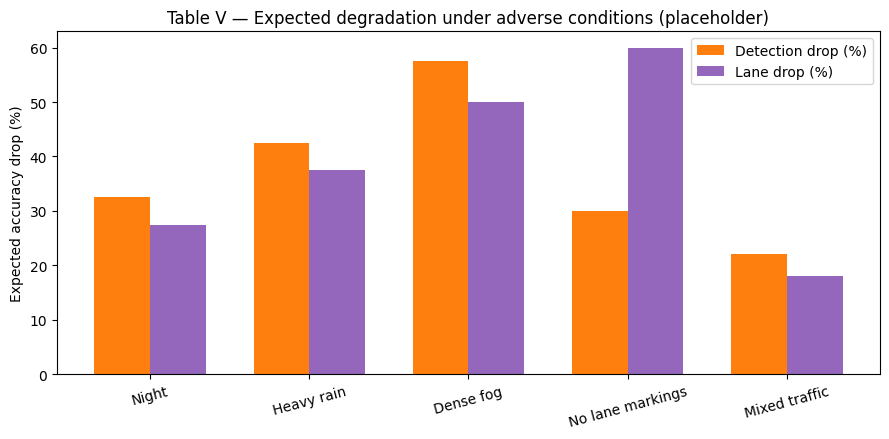

In [ ]:
import pandas as pd

# --- Table II: reference-implementation output on the current sample frame ---
table_ii = pd.DataFrame([
    {'Class': d['class'], 'Conf.': round(d['conf'], 2),
     'd_geo (m)': round(d.get('distance_m', geometric_distance(d['bbox'], d['class'])), 1),
     'Risk zone': d['zone']}
    for d in dets
])
print('Table II — Reference-implementation output, current frame')
display(table_ii)

# --- Table IV: target performance metrics by module (static, from the paper) ---
table_iv = pd.DataFrame([
    {'Module': 'Object Detection', 'Metric': 'mAP@0.5', 'Target': '70-85%', 'Dataset': 'KITTI/BDD100K'},
    {'Module': 'Object Detection', 'Metric': 'Inference speed', 'Target': '>=30 FPS', 'Dataset': 'GPU'},
    {'Module': 'Lane Detection', 'Metric': 'F1 score (overall)', 'Target': '70-78%', 'Dataset': 'CULane'},
    {'Module': 'Lane Detection', 'Metric': 'F1 score (no-line)', 'Target': '>=50%', 'Dataset': 'CULane'},
    {'Module': 'Distance Estimation', 'Metric': 'MAE (fused)', 'Target': '1-3 m', 'Dataset': 'Simulation GT'},
    {'Module': 'Full Pipeline', 'Metric': 'End-to-end latency', 'Target': '>=30 FPS', 'Dataset': 'GPU'},
])
print('\nTable IV — Target performance metrics by module (pending full benchmark evaluation)')
display(table_iv)

# --- Table V: expected detection/lane accuracy degradation under adverse conditions ---
table_v = pd.DataFrame([
    {'Condition': 'Night', 'Detection Drop': '~30-35%', 'Lane Drop': '~25-30%'},
    {'Condition': 'Heavy rain', 'Detection Drop': '~40-45%', 'Lane Drop': '~35-40%'},
    {'Condition': 'Dense fog', 'Detection Drop': '~55-60%', 'Lane Drop': '~48-52%'},
    {'Condition': 'No lane markings', 'Detection Drop': '~28-32%', 'Lane Drop': '~58-62%'},
    {'Condition': 'Mixed traffic', 'Detection Drop': '~20-24%', 'Lane Drop': '~16-20%'},
])
print('\nTable V — Expected detection accuracy degradation under adverse conditions (placeholder)')
display(table_v)

# Visualize Table V as a grouped bar chart
def _mid(pct_range):
    lo, hi = pct_range.replace('~', '').replace('%', '').split('-')
    return (float(lo) + float(hi)) / 2

conditions = table_v['Condition']
det_drop = table_v['Detection Drop'].apply(_mid)
lane_drop = table_v['Lane Drop'].apply(_mid)
x = np.arange(len(conditions))
width = 0.35

plt.figure(figsize=(9, 4.5))
plt.bar(x - width/2, det_drop, width, label='Detection drop (%)', color='tab:orange')
plt.bar(x + width/2, lane_drop, width, label='Lane drop (%)', color='tab:purple')
plt.xticks(x, conditions, rotation=15)
plt.ylabel('Expected accuracy drop (%)')
plt.title('Table V — Expected degradation under adverse conditions (placeholder)')
plt.legend()
plt.tight_layout()
plt.show()

# To export once you have real numbers:
# table_ii.to_csv('table_ii.csv', index=False)
# print(table_iv.to_latex(index=False))

## Notes for filling in my paper's Table II / III with real numbers

- **Object detection**: point `detector` at KITTI/BDD100K image+label pairs, run `run_detection`, and call `mAP_at_50`.
- **Lane detection**: swap in CULane images per scenario category (`normal`, `crowded`, `night`, `no-line`, ...) and call `lane_f1` against the provided binary masks.
- **Distance estimation**: fit `DEPTH_SCALE_S` / `DEPTH_SHIFT_T` (Eq. 8) on a calibration split with LiDAR ground truth, then call `distance_mae` stratified by range bucket (<20 m / ≥20 m) to reproduce the fused-vs-individual comparison discussed in Section VI.
- **Throughput**: rerun Section 9 on your actual target hardware (RTX 3060 / Jetson Nano) for the FPS row.
- For CARLA-based edge-case testing (rain, fog, no-line, mixed traffic), swap `input_path` for frames exported from a CARLA scenario recording and rerun Sections 3–7.

## Datasets Used in Autonomous Driving Perception

Here's a brief overview of the datasets mentioned in the context of this notebook, and their typical use cases in autonomous driving research:

*   **KITTI (Karlsruhe Institute of Technology and Toyota Technological Institute)**:
    *   **Purpose**: One of the most widely used datasets for autonomous driving research. It provides real-world data collected from a moving platform equipped with cameras, lidar, and GPS/IMU systems.
    *   **Relevance**: Primarily used for benchmarking tasks like 3D object detection, 3D object tracking, visual odometry, stereo vision, and depth estimation. It's often referenced for evaluating the performance of perception algorithms in structured urban and rural environments.

*   **BDD100K (Berkeley DeepDrive 100K)**:
    *   **Purpose**: A large-scale, diverse dataset for driving scene understanding, featuring over 100,000 video sequences. It includes diverse scenes, weather conditions, and times of day.
    *   **Relevance**: Excellent for tasks like object detection (cars, pedestrians, traffic lights, etc.), semantic segmentation, drivable area segmentation, and lane detection, especially for models that need to generalize across various environmental conditions.

*   **CULane (Chinese University of Hong Kong Lane Detection Dataset)**:
    *   **Purpose**: Specifically designed for robust lane detection under challenging conditions, such as crowded scenes, night, and various weather conditions.
    *   **Relevance**: Focuses on the performance of lane detection algorithms, particularly in scenarios where lane markings are degraded or obscured, which is critical for real-world autonomous driving.

*   **IDD (Indian Driving Dataset)**:
    *   **Purpose**: This dataset addresses the challenge of autonomous driving in unstructured and diverse traffic scenarios, typical of developing countries like India. It features highly varied road conditions, traffic patterns, and object types not commonly found in Western datasets.
    *   **Relevance**: Crucial for developing and testing perception systems that need to operate reliably in complex, heterogeneous traffic environments, including detection of unique vehicle types (like auto-rickshaws, as mentioned in your code) and less regulated driving behaviors.

In [ ]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

USE_UPLOAD_BATCH = True
IMAGE_FOLDER = 'my_images'

Saving WhatsApp Image 2026-09-18 at 15.14.58.jpeg to WhatsApp Image 2026-09-18 at 15.14.58.jpeg
Found 1 images: ['WhatsApp Image 2026-09-18 at 15.14.58.jpeg']


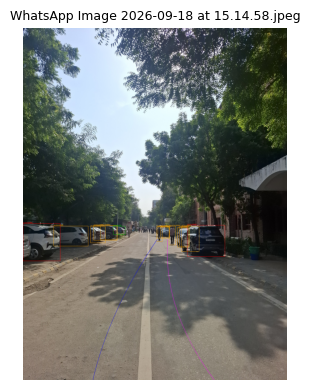

,image,n_detections,n_danger,n_warning,n_safe
0,WhatsApp Image 2026-09-18 at 15.14.58.jpeg,14,2,11,1


In [ ]:
# @title
USE_UPLOAD_BATCH = True
IMAGE_FOLDER = 'my_images'
USE_UPLOAD_BATCH = True  # True: upload images now. False: read from IMAGE_FOLDER below.
IMAGE_FOLDER = 'my_images'  # used when USE_UPLOAD_BATCH = False

if USE_UPLOAD_BATCH:
    from google.colab import files
    uploaded_batch = files.upload()  # select as many image files as you want
    image_paths = list(uploaded_batch.keys())
else:
    exts = ('.jpg', '.jpeg', '.png', '.bmp')
    image_paths = sorted(
        str(p) for p in Path(IMAGE_FOLDER).iterdir() if p.suffix.lower() in exts
    )

print(f'Found {len(image_paths)} images:', image_paths)

def run_pipeline_on_image(path):
    """Full per-frame pipeline (Sections 3-6), no ground truth required."""
    frame = cv2.imread(path)
    if frame is None:
        return None
    frame_dets, _ = run_detection(frame)
    depth_map_ = predict_relative_depth(frame)
    xs_, ys_, _ = detect_lane_pixels(frame)
    left_c_ = fit_lane_polynomial(xs_, ys_, 'left', frame.shape[1])
    right_c_ = fit_lane_polynomial(xs_, ys_, 'right', frame.shape[1])
    for d in frame_dets:
        d_geo_ = geometric_distance(d['bbox'], d['class'])
        d_mid_ = midas_distance(d['bbox'], depth_map_)
        d['distance_m'] = fuse_distance(d_geo_, d_mid_)
        d['zone'] = risk_zone(d['distance_m'])
    frame_tracker = SimpleSORT()  # fresh tracker per unrelated image
    frame_dets = frame_tracker.update(frame_dets)
    return frame, frame_dets, left_c_, right_c_

def draw_result(frame, frame_dets, left_c_, right_c_):
    vis_ = frame.copy()
    zc = {'DANGER': (0,0,255), 'WARNING': (0,165,255), 'SAFE': (0,200,0)}
    for d in frame_dets:
        x1,y1,x2,y2 = [int(v) for v in d['bbox']]
        c = zc[d['zone']]
        cv2.rectangle(vis_, (x1,y1), (x2,y2), c, 2)
        label = f"{d['class']} {d['distance_m']:.1f}m {d['zone']}"
        cv2.putText(vis_, label, (x1, max(y1-6,0)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 2)
    fh = frame.shape[0]
    for coeffs, color in [(left_c_, (255,0,0)), (right_c_, (255,0,255))]:
        if coeffs is None:
            continue
        yy = np.linspace(int(fh*0.6), fh-1, 50)
        xx = np.polyval(coeffs, yy)
        pts = np.array([xx, yy]).T.astype(np.int32)
        cv2.polylines(vis_, [pts], False, color, 2)
    return cv2.cvtColor(vis_, cv2.COLOR_BGR2RGB)

batch_results = []
for p in image_paths:
    result = run_pipeline_on_image(p)
    if result is None:
        print(f'Skipping unreadable file: {p}')
        continue
    batch_results.append((p, *result))

n = len(batch_results)
cols = min(3, max(n, 1))
rows = (n + cols - 1) // cols
plt.figure(figsize=(5*cols, 4*rows))
for i, (p, frame, frame_dets, left_c_, right_c_) in enumerate(batch_results):
    plt.subplot(rows, cols, i+1)
    plt.imshow(draw_result(frame, frame_dets, left_c_, right_c_))
    plt.title(Path(p).name, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

# Summary table across all uploaded images (no ground truth involved)
summary_rows = []
for p, frame, frame_dets, _, _ in batch_results:
    summary_rows.append({
        'image': Path(p).name,
        'n_detections': len(frame_dets),
        'n_danger': sum(1 for d in frame_dets if d['zone'] == 'DANGER'),
        'n_warning': sum(1 for d in frame_dets if d['zone'] == 'WARNING'),
        'n_safe': sum(1 for d in frame_dets if d['zone'] == 'SAFE'),
    })
import pandas as pd
batch_summary = pd.DataFrame(summary_rows)
display(batch_summary)

Saving -1x-1.webp to -1x-1 (1).webp
Found 1 images: ['-1x-1 (1).webp']


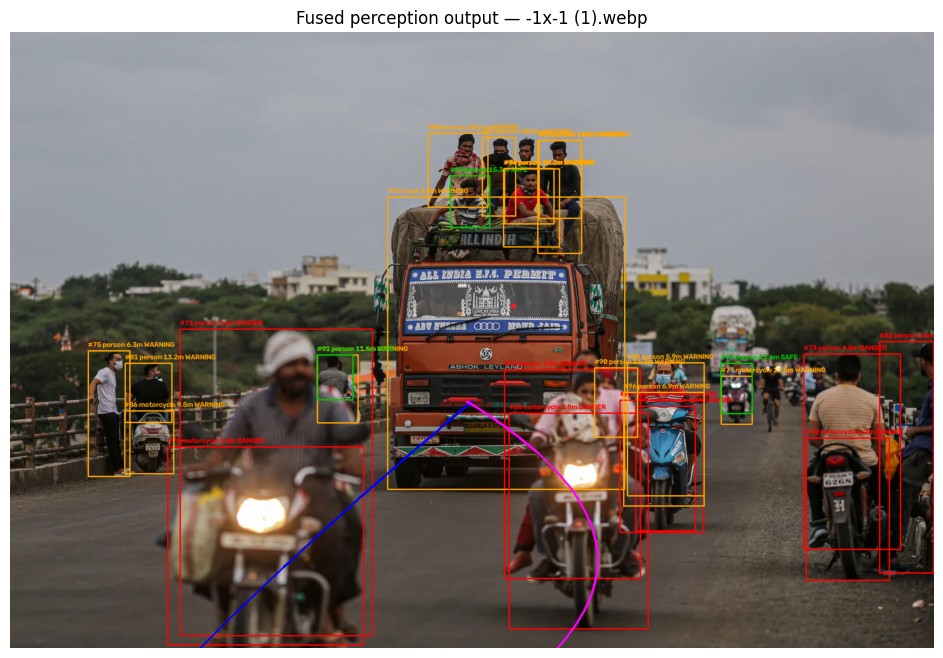

--- -1x-1 (1).webp: 27 detections ---
track#71        person  conf=0.85  dist=2.6 m  zone=DANGER
track#72    motorcycle  conf=0.79  dist=4.2 m  zone=DANGER
track#73        person  conf=0.79  dist=4.0 m  zone=DANGER
track#74        person  conf=0.79  dist=3.8 m  zone=DANGER
track#75        person  conf=0.72  dist=6.3 m  zone=WARNING
track#76         truck  conf=0.62  dist=5.5 m  zone=WARNING
track#77    motorcycle  conf=0.62  dist=12.5 m  zone=WARNING
track#78    motorcycle  conf=0.59  dist=3.0 m  zone=DANGER
track#79    motorcycle  conf=0.58  dist=4.8 m  zone=DANGER
track#80        person  conf=0.54  dist=10.6 m  zone=WARNING
track#81        person  conf=0.54  dist=13.2 m  zone=WARNING
track#82        person  conf=0.53  dist=3.4 m  zone=DANGER
track#83        person  conf=0.52  dist=10.0 m  zone=WARNING
track#84        person  conf=0.51  dist=14.2 m  zone=WARNING
track#85    motorcycle  conf=0.46  dist=4.5 m  zone=DANGER
track#86    motorcycle  conf=0.46  dist=9.5 m  zone=WARNING
track

,image,n_detections,n_danger,n_warning,n_safe
0,-1x-1 (1).webp,27,9,15,3


In [ ]:
USE_UPLOAD_BATCH = True  # True: upload images now. False: read from IMAGE_FOLDER below.
IMAGE_FOLDER = 'my_images'  # used when USE_UPLOAD_BATCH = False

if USE_UPLOAD_BATCH:
    from google.colab import files
    uploaded_batch = files.upload()  # select as many image files as you want
    image_paths = list(uploaded_batch.keys())
else:
    exts = ('.jpg', '.jpeg', '.png', '.bmp')
    image_paths = sorted(
        str(p) for p in Path(IMAGE_FOLDER).iterdir() if p.suffix.lower() in exts
    )

print(f'Found {len(image_paths)} images:', image_paths)

def run_pipeline_on_image(path):
    """Full per-frame pipeline (Sections 3-6), no ground truth required."""
    frame = cv2.imread(path)
    if frame is None:
        return None
    frame_dets, _ = run_detection(frame)
    depth_map_ = predict_relative_depth(frame)
    xs_, ys_, _ = detect_lane_pixels(frame)
    left_c_ = fit_lane_polynomial(xs_, ys_, 'left', frame.shape[1])
    right_c_ = fit_lane_polynomial(xs_, ys_, 'right', frame.shape[1])
    for d in frame_dets:
        d_geo_ = geometric_distance(d['bbox'], d['class'])
        d_mid_ = midas_distance(d['bbox'], depth_map_)
        d['distance_m'] = fuse_distance(d_geo_, d_mid_)
        d['zone'] = risk_zone(d['distance_m'])
    frame_tracker = SimpleSORT()  # fresh tracker per unrelated image
    frame_dets = frame_tracker.update(frame_dets)
    return frame, frame_dets, left_c_, right_c_

def draw_result(frame, frame_dets, left_c_, right_c_):
    """Same style as Section 7: bbox + track id + class + distance + zone, lane curves."""
    vis_ = frame.copy()
    zc = {'DANGER': (0,0,255), 'WARNING': (0,165,255), 'SAFE': (0,200,0)}
    for d in frame_dets:
        x1,y1,x2,y2 = [int(v) for v in d['bbox']]
        c = zc[d['zone']]
        cv2.rectangle(vis_, (x1,y1), (x2,y2), c, 2)
        label = f"#{d['track_id']} {d['class']} {d['distance_m']:.1f}m {d['zone']}"
        cv2.putText(vis_, label, (x1, max(y1-8,0)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 2)
    fh = frame.shape[0]
    for coeffs, color in [(left_c_, (255,0,0)), (right_c_, (255,0,255))]:
        if coeffs is None:
            continue
        yy = np.linspace(int(fh*0.6), fh-1, 50)
        xx = np.polyval(coeffs, yy)
        pts = np.array([xx, yy]).T.astype(np.int32)
        cv2.polylines(vis_, [pts], False, color, 3)
    return cv2.cvtColor(vis_, cv2.COLOR_BGR2RGB)

# --- Full-size, one figure per image (matches Section 7's presentation) ---
batch_results = []
for p in image_paths:
    result = run_pipeline_on_image(p)
    if result is None:
        print(f'Skipping unreadable file: {p}')
        continue
    frame, frame_dets, left_c_, right_c_ = result
    batch_results.append((p, frame, frame_dets, left_c_, right_c_))

    plt.figure(figsize=(12, 8))
    plt.imshow(draw_result(frame, frame_dets, left_c_, right_c_))
    plt.axis('off')
    plt.title(f'Fused perception output — {Path(p).name}')
    plt.show()

    # Per-detection printout, same format as Sections 5/6
    print(f"--- {Path(p).name}: {len(frame_dets)} detections ---")
    for d in frame_dets:
        print(f"track#{d['track_id']}  {d['class']:>12s}  conf={d['conf']:.2f}  "
              f"dist={d['distance_m']:.1f} m  zone={d['zone']}")
    print()

# Summary table across all images (no ground truth involved)
summary_rows = []
for p, frame, frame_dets, _, _ in batch_results:
    summary_rows.append({
        'image': Path(p).name,
        'n_detections': len(frame_dets),
        'n_danger': sum(1 for d in frame_dets if d['zone'] == 'DANGER'),
        'n_warning': sum(1 for d in frame_dets if d['zone'] == 'WARNING'),
        'n_safe': sum(1 for d in frame_dets if d['zone'] == 'SAFE'),
    })
batch_summary = pd.DataFrame(summary_rows)
display(batch_summary)

Running benchmark on CPU...
CPU End-to-End Pipeline: 4.04 FPS
Running benchmark on GPU...
GPU End-to-End Pipeline: 18.30 FPS


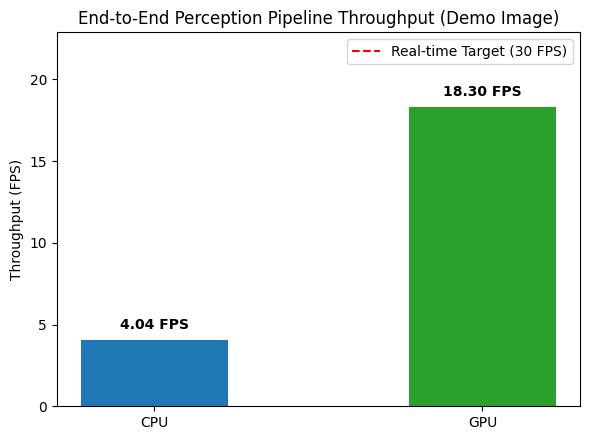

In [ ]:
import time
import torch
import matplotlib.pyplot as plt

# Prepare temporary tracker and pipeline for benchmark
def benchmark_pipeline(device_type):
    global device
    old_device = device
    device = device_type  # Temporarily override global device so preprocessing utilities send inputs correctly

    # Move models to target device
    detector.to(device_type)
    if 'midas' in globals():
        midas.to(device_type)

    # Warm up run
    test_tracker = SimpleSORT()
    _ = process_frame(img, test_tracker)
    if device_type == 'cuda':
        torch.cuda.synchronize()

    # Execution benchmark loop
    n_runs = 5
    start_time = time.time()
    for _ in range(n_runs):
        _ = process_frame(img, test_tracker)
    if device_type == 'cuda':
        torch.cuda.synchronize()

    elapsed = time.time() - start_time
    fps = n_runs / elapsed

    device = old_device  # Restore original device
    return fps

# --- Run benchmark on CPU ---
print("Running benchmark on CPU...")
cpu_pipeline_fps = benchmark_pipeline('cpu')
print(f"CPU End-to-End Pipeline: {cpu_pipeline_fps:.2f} FPS")

# --- Run benchmark on GPU ---
if torch.cuda.is_available():
    print("Running benchmark on GPU...")
    gpu_pipeline_fps = benchmark_pipeline('cuda')
    print(f"GPU End-to-End Pipeline: {gpu_pipeline_fps:.2f} FPS")
    # Restore detector and midas back to default GPU device
    detector.to('cuda')
    if 'midas' in globals():
        midas.to('cuda')
else:
    gpu_pipeline_fps = None
    print("GPU device is not available.")

# --- Visualize FPS comparison ---
devices = ['CPU']
fps_values = [cpu_pipeline_fps]
colors = ['tab:blue']

if gpu_pipeline_fps is not None:
    devices.append('GPU')
    fps_values.append(gpu_pipeline_fps)
    colors.append('tab:green')

plt.figure(figsize=(6, 4.5))
bars = plt.bar(devices, fps_values, color=colors, width=0.45)
plt.ylabel('Throughput (FPS)')
plt.title('End-to-End Perception Pipeline Throughput (Demo Image)')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f'{yval:.2f} FPS', va='bottom', ha='center', fontweight='bold')

plt.axhline(30.0, color='red', linestyle='--', linewidth=1.5, label='Real-time Target (30 FPS)')
plt.ylim(0, max(fps_values) * 1.25 if gpu_pipeline_fps else 40)
plt.legend()
plt.tight_layout()
plt.show()